In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv(r"C:\Users\SAFAR\Desktop\assignment kiddo.csv")

In [6]:
import sys
!{sys.executable} -m pip install seaborn


[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import sys
print(sys.executable)

c:\Users\SAFAR\AppData\Local\Programs\Python\Python311\python.exe


In [2]:
df.head(5)

,Order ID,Total Amount,Created At,Status,Rider Name,Rider Contact,Delivery Status,Expected ETA,Delay Reason,Scheduled Date,Scheduled Time,Packing Duration,Picked Up Duration,Out for Delivery Duration,Reached Delivery Duration,Reached Delivery Timestamp,Delivered Duration,Delivered Timestamp
0,#18405,-,6/30/2026 23:59,cancelled,Unassigned,-,Delayed (+3783 mins),49 minutes,Item NA at store,On-Time,-,-,-,-,-,-,-,-
1,#18404,-,6/30/2026 23:54,delivered,sandeep Kiddo,8057924668,Delayed (+4 mins),60 minutes,-,-,-,0m,3m,0m,1h 0m,7/1/2026 0:58,0m,7/1/2026 0:59
2,#18403,-,6/30/2026 23:54,delivered,Robin SFX,7982753727,On-Time,60 minutes,-,1/7/2026,12:00,3h 2m,8h 7m,-,-,7/1/2026 11:41,0m,7/1/2026 11:42
3,#18402,-,6/30/2026 23:53,delivered,ROSHAN KUMARSFX,8423838078,Delayed (+10 mins),49 minutes,rider not avilabile,1/7/2026,7:00,3h 6m,4h 38m,3m,29m,7/1/2026 8:10,5m,7/1/2026 8:16
4,#18401,-,6/30/2026 23:51,delivered,AKASH THAKURSFX,9576234127,On-Time,53 minutes,-,1/7/2026,10:00,3h 10m,6h 18m,18m,12m,7/1/2026 9:51,9m,7/1/2026 10:01


In [3]:
df.shape

(8717, 18)

In [4]:
df.describe()

,Order ID,Total Amount,Created At,Status,Rider Name,Rider Contact,Delivery Status,Expected ETA,Delay Reason,Scheduled Date,Scheduled Time,Packing Duration,Picked Up Duration,Out for Delivery Duration,Reached Delivery Duration,Reached Delivery Timestamp,Delivered Duration,Delivered Timestamp
count,8717,8717,8717,8717,8717,8717,8717,8717,8695,8717,8717,8717,8717,8717,8717,8717,8717,8717
unique,4359,2,4037,12,179,180,622,91,445,36,20,287,253,54,137,3486,173,3450
top,#18405,-,6/24/2026 18:30,delivered,Unassigned,-,On-Time,33 minutes,-,-,-,1m,2m,0m,-,-,-,-
freq,2,8716,8,7424,846,846,5640,320,6378,7563,7564,2116,1520,3762,2230,1230,1576,1268


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8717 entries, 0 to 8716
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Order ID                    8717 non-null   str  
 1   Total Amount                8717 non-null   str  
 2   Created At                  8717 non-null   str  
 3   Status                      8717 non-null   str  
 4   Rider Name                  8717 non-null   str  
 5   Rider Contact               8717 non-null   str  
 6   Delivery Status             8717 non-null   str  
 7   Expected ETA                8717 non-null   str  
 8   Delay Reason                8695 non-null   str  
 9   Scheduled Date              8717 non-null   str  
 10  Scheduled Time              8717 non-null   str  
 11  Packing Duration            8717 non-null   str  
 12  Picked Up Duration          8717 non-null   str  
 13  Out for Delivery Duration   8717 non-null   str  
 14  Reached Delivery Du

In [6]:
df.isnull().sum()

Order ID                       0
Total Amount                   0
Created At                     0
Status                         0
Rider Name                     0
Rider Contact                  0
Delivery Status                0
Expected ETA                   0
Delay Reason                  22
Scheduled Date                 0
Scheduled Time                 0
Packing Duration               0
Picked Up Duration             0
Out for Delivery Duration      0
Reached Delivery Duration      0
Reached Delivery Timestamp     0
Delivered Duration             0
Delivered Timestamp            0
dtype: int64

In [7]:
df.dtypes

Order ID                      str
Total Amount                  str
Created At                    str
Status                        str
Rider Name                    str
Rider Contact                 str
Delivery Status               str
Expected ETA                  str
Delay Reason                  str
Scheduled Date                str
Scheduled Time                str
Packing Duration              str
Picked Up Duration            str
Out for Delivery Duration     str
Reached Delivery Duration     str
Reached Delivery Timestamp    str
Delivered Duration            str
Delivered Timestamp           str
dtype: object

In [8]:
df = df[df['Order ID'] != 'Order ID'].copy()
df.reset_index(drop=True, inplace=True)
print(df.shape)
df['Status'].value_counts()

(8716, 18)


Status
delivered           7424
cancelled            786
reached_delivery     164
packing              102
out_for_delivery      92
packed                70
rider_assigned        40
refunded              26
returned               8
placed                 2
exchanged              2
Name: count, dtype: int64

In [9]:
df['Created At'] = pd.to_datetime(df['Created At'], format='%m/%d/%Y %H:%M', errors='coerce')
df['Reached Delivery Timestamp'] = pd.to_datetime(df['Reached Delivery Timestamp'], format='%m/%d/%Y %H:%M', errors='coerce')
df['Delivered Timestamp'] = pd.to_datetime(df['Delivered Timestamp'], format='%m/%d/%Y %H:%M', errors='coerce')

df[['Created At','Delivered Timestamp']].head()

,Created At,Delivered Timestamp
0,2026-06-30 23:59:00,NaT
1,2026-06-30 23:54:00,2026-07-01 00:59:00
2,2026-06-30 23:54:00,2026-07-01 11:42:00
3,2026-06-30 23:53:00,2026-07-01 08:16:00
4,2026-06-30 23:51:00,2026-07-01 10:01:00


In [10]:
df['Order_Date'] = df['Created At'].dt.date
df['Order_Time'] = df['Created At'].dt.time

df[['Created At', 'Order_Date', 'Order_Time']].head()

,Created At,Order_Date,Order_Time
0,2026-06-30 23:59:00,2026-06-30,23:59:00
1,2026-06-30 23:54:00,2026-06-30,23:54:00
2,2026-06-30 23:54:00,2026-06-30,23:54:00
3,2026-06-30 23:53:00,2026-06-30,23:53:00
4,2026-06-30 23:51:00,2026-06-30,23:51:00


In [11]:
def duration_to_minutes(val):
    if pd.isna(val) or str(val).strip() == '-' or str(val).strip() == '':
        return np.nan
    val = str(val).strip()
    hours, minutes = 0, 0
    if 'h' in val:
        parts = val.split('h')
        hours = int(parts[0].strip())
        rest = parts[1].replace('m','').strip()
        minutes = int(rest) if rest != '' else 0
    elif 'm' in val:
        minutes = int(val.replace('m','').strip())
    return hours*60 + minutes

duration_cols = ['Packing Duration', 'Picked Up Duration', 'Out for Delivery Duration',
                  'Reached Delivery Duration', 'Delivered Duration']

for col in duration_cols:
    df[col + '_min'] = df[col].apply(duration_to_minutes)

df[[c+'_min' for c in duration_cols]].describe()

,Packing Duration_min,Picked Up Duration_min,Out for Delivery Duration_min,Reached Delivery Duration_min,Delivered Duration_min
count,8090.000000,7824.000000,6792.000000,6486.000000,7140.000000
mean,41.794314,28.100460,2.153121,36.169904,41.768347
std,352.586647,119.022556,6.189811,76.863181,485.328006
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,2.000000,0.000000,18.000000,4.000000
50%,2.000000,3.000000,0.000000,31.000000,8.000000
75%,5.000000,6.000000,1.000000,44.000000,16.000000
max,16771.000000,2275.000000,82.000000,2772.000000,22884.000000


In [12]:
df['Expected ETA_min'] = df['Expected ETA'].astype(str).str.extract(r'(\d+)').astype(float)


In [13]:
def extract_delay(val):
    val = str(val)
    if 'On-Time' in val:
        return 0
    if '+' in val:
        try:
            return int(val.split('+')[1].split(' mins')[0].strip())
        except:
            return np.nan
    return np.nan

df['Delay_minutes'] = df['Delivery Status'].apply(extract_delay)
df['Is_OnTime'] = df['Delivery Status'].astype(str).str.contains('On-Time')

df[['Delivery Status','Delay_minutes','Is_OnTime','Expected ETA_min']].head(10)

,Delivery Status,Delay_minutes,Is_OnTime,Expected ETA_min
0,Delayed (+3783 mins),3783.0,False,49.0
1,Delayed (+4 mins),4.0,False,60.0
2,On-Time,0.0,True,60.0
3,Delayed (+10 mins),10.0,False,49.0
4,On-Time,0.0,True,53.0
5,Delayed (+3352 mins),3352.0,False,56.0
6,On-Time,0.0,True,60.0
7,Delayed (+13 mins),13.0,False,60.0
8,Delayed (+17 mins),17.0,False,60.0
9,On-Time,0.0,True,25.0


In [14]:
df['DayOfWeek'] = df['Created At'].dt.day_name()
df['Is_Weekend'] = df['Created At'].dt.dayofweek >= 5
df['Hour'] = df['Created At'].dt.hour
df['Date'] = df['Created At'].dt.date

df[['Created At','DayOfWeek','Is_Weekend','Hour']].head()

,Created At,DayOfWeek,Is_Weekend,Hour
0,2026-06-30 23:59:00,Tuesday,False,23
1,2026-06-30 23:54:00,Tuesday,False,23
2,2026-06-30 23:54:00,Tuesday,False,23
3,2026-06-30 23:53:00,Tuesday,False,23
4,2026-06-30 23:51:00,Tuesday,False,23


In [15]:
df['Total_Delivery_Time_min'] = (df['Delivered Timestamp'] - df['Created At']).dt.total_seconds() / 60


In [16]:
delivered_df = df[(df['Status'] == 'delivered') & (df['Total_Delivery_Time_min'] > 0) & (df['Total_Delivery_Time_min'] < 300)].copy()
print("Delivered valid orders:", delivered_df.shape[0])
delivered_df['Total_Delivery_Time_min'].describe()

Delivered valid orders: 6746


count    6746.000000
mean       61.391047
std        34.664604
min         2.000000
25%        41.000000
50%        55.000000
75%        72.000000
max       298.000000
Name: Total_Delivery_Time_min, dtype: float64

Total Orders: 8716
Weekday Orders: 6258 (71.8%)
Weekend Orders: 2458 (28.2%)
Avg Orders/Weekday: 284.5
Avg Orders/Weekend Day: 307.2


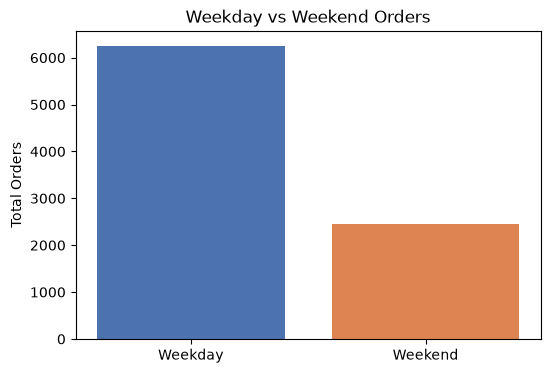

In [17]:
weekend_orders = df[df['Is_Weekend']].shape[0]
weekday_orders = df[~df['Is_Weekend']].shape[0]
total_orders = df.shape[0]

num_weekday_days = df[~df['Is_Weekend']]['Date'].nunique()
num_weekend_days = df[df['Is_Weekend']]['Date'].nunique()

avg_weekday = weekday_orders / num_weekday_days if num_weekday_days else 0
avg_weekend = weekend_orders / num_weekend_days if num_weekend_days else 0

print(f"Total Orders: {total_orders}")
print(f"Weekday Orders: {weekday_orders} ({weekday_orders/total_orders*100:.1f}%)")
print(f"Weekend Orders: {weekend_orders} ({weekend_orders/total_orders*100:.1f}%)")
print(f"Avg Orders/Weekday: {avg_weekday:.1f}")
print(f"Avg Orders/Weekend Day: {avg_weekend:.1f}")

plt.figure(figsize=(6,4))
plt.bar(['Weekday','Weekend'], [weekday_orders, weekend_orders], color=['#4C72B0','#DD8452'])
plt.title('Weekday vs Weekend Orders')
plt.ylabel('Total Orders')
plt.savefig('weekday_vs_weekend.png', dpi=150, bbox_inches='tight')
plt.show()

Hour
0     204
1      80
2      26
3      18
4      16
5      12
6      40
7     124
8     206
9     368
10    478
11    588
12    618
13    582
14    564
15    512
16    534
17    542
18    662
19    634
20    558
21    538
22    446
23    366
dtype: int64

Riders needed per hour:
 Hour
0      82.0
1      32.0
2      11.0
3       8.0
4       7.0
5       5.0
6      16.0
7      50.0
8      83.0
9     148.0
10    192.0
11    236.0
12    248.0
13    233.0
14    226.0
15    205.0
16    214.0
17    217.0
18    265.0
19    254.0
20    224.0
21    216.0
22    179.0
23    147.0
dtype: float64

Shift 1 (6AM-2PM): 3004 orders, riders needed: 151.0
Shift 2 (2PM-10PM): 4544 orders, riders needed: 228.0
Shift 3 (10PM-6AM): 1168 orders, riders needed: 59.0


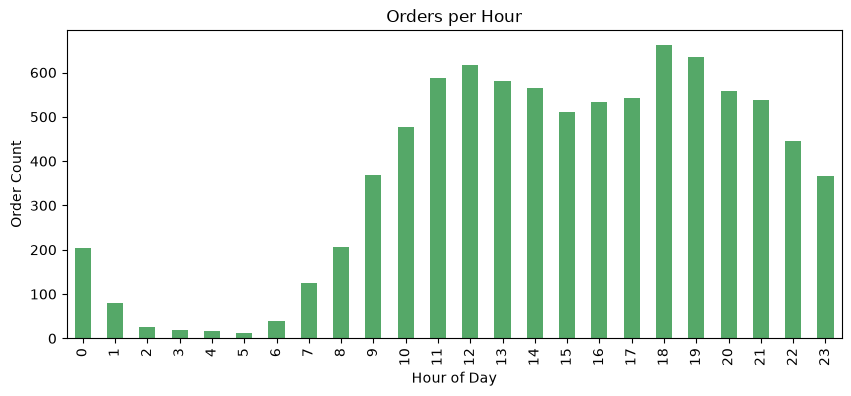

In [18]:
orders_per_hour = df.groupby('Hour').size()
print(orders_per_hour)

avg_capacity_per_rider = 2.5   # assumption: 1 rider handles 2.5 orders/hour
riders_needed = (orders_per_hour / avg_capacity_per_rider).apply(np.ceil)
print("\nRiders needed per hour:\n", riders_needed)

shift1 = orders_per_hour.reindex(range(6,14), fill_value=0).sum()   # 6AM-2PM
shift2 = orders_per_hour.reindex(range(14,22), fill_value=0).sum()  # 2PM-10PM
shift3 = orders_per_hour.reindex(list(range(22,24))+list(range(0,6)), fill_value=0).sum()  # 10PM-6AM

print(f"\nShift 1 (6AM-2PM): {shift1} orders, riders needed: {np.ceil(shift1/8/avg_capacity_per_rider)}")
print(f"Shift 2 (2PM-10PM): {shift2} orders, riders needed: {np.ceil(shift2/8/avg_capacity_per_rider)}")
print(f"Shift 3 (10PM-6AM): {shift3} orders, riders needed: {np.ceil(shift3/8/avg_capacity_per_rider)}")

plt.figure(figsize=(10,4))
orders_per_hour.plot(kind='bar', color='#55A868')
plt.title('Orders per Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Order Count')
plt.savefig('orders_per_hour.png', dpi=150, bbox_inches='tight')
plt.show()

On-Time %: 64.7%
Delayed %: 35.3%
Avg Delay (minutes): 7316.1

Stage-wise Avg Duration (minutes):
Packing Duration_min             41.794314
Delivered Duration_min           41.768347
Reached Delivery Duration_min    36.169904
Picked Up Duration_min           28.100460
Out for Delivery Duration_min     2.153121
dtype: float64


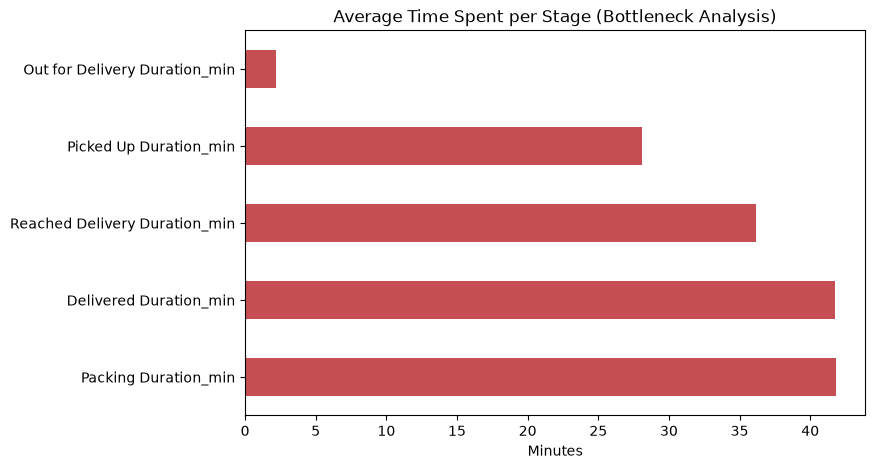

In [19]:
valid_status_df = df[df['Delivery Status'].notna()].copy()

pct_on_time = valid_status_df['Is_OnTime'].mean() * 100
pct_late = 100 - pct_on_time
avg_delay = valid_status_df[valid_status_df['Delay_minutes'] > 0]['Delay_minutes'].mean()

print(f"On-Time %: {pct_on_time:.1f}%")
print(f"Delayed %: {pct_late:.1f}%")
print(f"Avg Delay (minutes): {avg_delay:.1f}")

stage_cols_min = [c+'_min' for c in duration_cols]
stage_avg = df[stage_cols_min].mean().sort_values(ascending=False)
print("\nStage-wise Avg Duration (minutes):")
print(stage_avg)

plt.figure(figsize=(8,5))
stage_avg.plot(kind='barh', color='#C44E52')
plt.title('Average Time Spent per Stage (Bottleneck Analysis)')
plt.xlabel('Minutes')
plt.savefig('stage_bottleneck.png', dpi=150, bbox_inches='tight')
plt.show()

In [21]:
realistic_delay_df = df[(df['Delay_minutes'] > 0) & (df['Delay_minutes'] < 200)]

top_delays = realistic_delay_df.nlargest(15, 'Delay_minutes')[['Order ID','Rider Name','Delay_minutes','Delay Reason']]
print(top_delays)

delay_reason_counts = df[df['Delay Reason'] != '-']['Delay Reason'].value_counts()
print("\nTop Delay Reasons:")
print(delay_reason_counts.head(15))

     Order ID         Rider Name  Delay_minutes                  Delay Reason
2765   #15485         Unassigned          199.0  Marked as delivered manually
7123   #15485         Unassigned          199.0  Marked as delivered manually
1624   #16688    Kailash Kailash          198.0        item nahi mil raha tha
5982   #16688    Kailash Kailash          198.0        item nahi mil raha tha
2913   #15337         Unassigned          193.0  Marked as delivered manually
7271   #15337         Unassigned          193.0  Marked as delivered manually
2544   #15706  Rakesh EvRecharge          178.0  Marked as delivered manually
6902   #15706  Rakesh EvRecharge          178.0  Marked as delivered manually
634    #17760        divakar sfx          177.0                             -
4992   #17760        divakar sfx          177.0                             -
3586   #14660   Rohit EvRecharge          170.0                             -
7944   #14660   Rohit EvRecharge          170.0                 

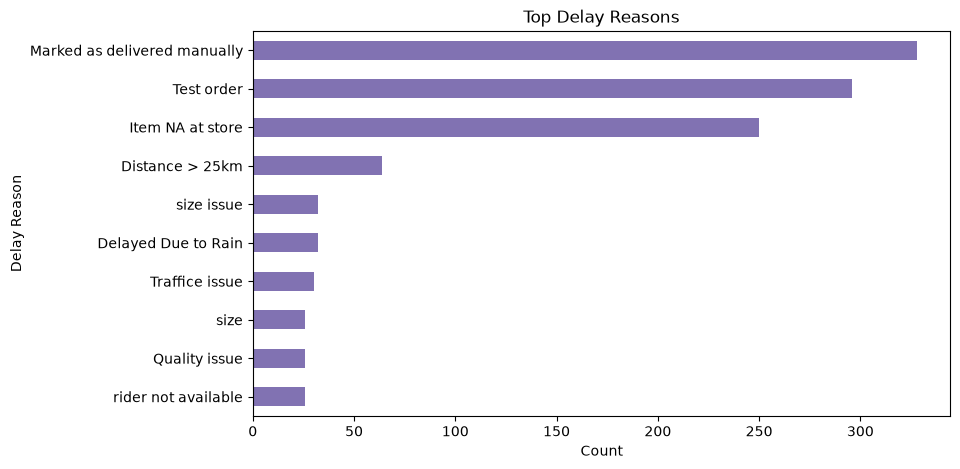

In [22]:
plt.figure(figsize=(9,5))
delay_reason_counts.head(10).plot(kind='barh', color='#8172B2')
plt.title('Top Delay Reasons')
plt.xlabel('Count')
plt.gca().invert_yaxis()
plt.savefig('delay_reasons.png', dpi=150, bbox_inches='tight')
plt.show()

Peak Hour: 18:00 with 662 orders

Top 3 Peak Hours:
 Hour
18    662
19    634
12    618
dtype: int64


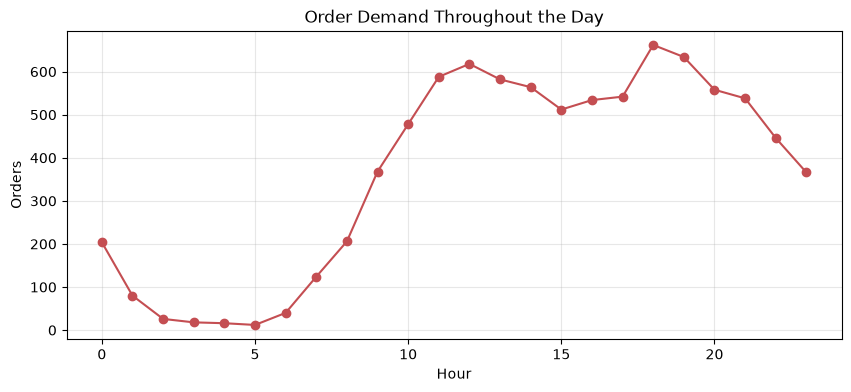

In [23]:
peak_hour = orders_per_hour.idxmax()
peak_hour_orders = orders_per_hour.max()
print(f"Peak Hour: {peak_hour}:00 with {peak_hour_orders} orders")

top3_peak = orders_per_hour.sort_values(ascending=False).head(3)
print("\nTop 3 Peak Hours:\n", top3_peak)

plt.figure(figsize=(10,4))
orders_per_hour.plot(kind='line', marker='o', color='#C44E52')
plt.title('Order Demand Throughout the Day')
plt.xlabel('Hour')
plt.ylabel('Orders')
plt.grid(True, alpha=0.3)
plt.savefig('peak_hour_trend.png', dpi=150, bbox_inches='tight')
plt.show()

In [24]:
avg_del_time = delivered_df['Total_Delivery_Time_min'].mean()
median_del_time = delivered_df['Total_Delivery_Time_min'].median()
fastest = delivered_df['Total_Delivery_Time_min'].min()
slowest = delivered_df['Total_Delivery_Time_min'].max()

print(f"Average Delivery Time: {avg_del_time:.1f} min")
print(f"Median Delivery Time: {median_del_time:.1f} min")
print(f"Fastest Delivery: {fastest:.1f} min")
print(f"Slowest Delivery: {slowest:.1f} min")

Average Delivery Time: 61.4 min
Median Delivery Time: 55.0 min
Fastest Delivery: 2.0 min
Slowest Delivery: 298.0 min


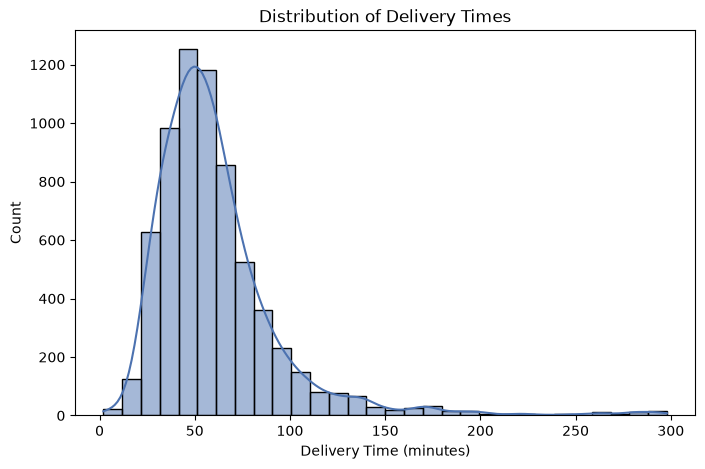

In [25]:
plt.figure(figsize=(8,5))
sns.histplot(delivered_df['Total_Delivery_Time_min'], bins=30, kde=True, color='#4C72B0')
plt.title('Distribution of Delivery Times')
plt.xlabel('Delivery Time (minutes)')
plt.savefig('delivery_time_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [26]:
avg_eta = delivered_df['Expected ETA_min'].mean()
avg_variance = (delivered_df['Total_Delivery_Time_min'] - delivered_df['Expected ETA_min']).mean()
eta_accuracy_pct = (delivered_df['Total_Delivery_Time_min'] <= delivered_df['Expected ETA_min']).mean() * 100

print(f"Average Expected ETA: {avg_eta:.1f} min")
print(f"Average Variance (Actual - Expected): {avg_variance:.1f} min")
print(f"ETA Accuracy (delivered within promised time): {eta_accuracy_pct:.1f}%")

Average Expected ETA: 50.7 min
Average Variance (Actual - Expected): 10.7 min
ETA Accuracy (delivered within promised time): 43.4%


In [27]:
variables_to_check = ['total_orders', 'weekday_orders', 'weekend_orders', 
                       'pct_on_time', 'pct_late', 'avg_delay', 
                       'peak_hour', 'peak_hour_orders', 
                       'avg_del_time', 'median_del_time', 'fastest', 'slowest',
                       'avg_eta', 'avg_variance', 'eta_accuracy_pct', 'stage_avg']

for var in variables_to_check:
    if var in dir():
        print(f"{var} = {eval(var)}")
    else:
        print(f" {var} — NOT DEFINED")

total_orders = 8716
weekday_orders = 6258
weekend_orders = 2458
pct_on_time = 64.70858191831115
pct_late = 35.291418081688846
avg_delay = 7316.057254391672
peak_hour = 18
peak_hour_orders = 662
avg_del_time = 61.39104654610139
median_del_time = 55.0
fastest = 2.0
slowest = 298.0
avg_eta = 50.66073546856465
avg_variance = 10.730427046263346
eta_accuracy_pct = 43.40349836940409
stage_avg = Packing Duration_min             41.794314
Delivered Duration_min           41.768347
Reached Delivery Duration_min    36.169904
Picked Up Duration_min           28.100460
Out for Delivery Duration_min     2.153121
dtype: float64


In [28]:
avg_delay = valid_status_df[(valid_status_df['Delay_minutes'] > 0) & (valid_status_df['Delay_minutes'] < 200)]['Delay_minutes'].mean()

In [29]:
print(avg_delay)

24.883011190233976


In [30]:
summary = {
    'Total Orders': total_orders,
    'Weekday Orders': weekday_orders,
    'Weekend Orders': weekend_orders,
    'Weekday %': round(weekday_orders/total_orders*100, 1),
    'Weekend %': round(weekend_orders/total_orders*100, 1),
    'On-Time %': round(pct_on_time, 1),
    'Delayed %': round(pct_late, 1),
    'Avg Delay (min)': round(avg_delay, 1),
    'Peak Hour': peak_hour,
    'Peak Hour Orders': peak_hour_orders,
    'Avg Delivery Time (min)': round(avg_del_time, 1),
    'Median Delivery Time (min)': round(median_del_time, 1),
    'Fastest Delivery (min)': round(fastest, 1),
    'Slowest Delivery (min)': round(slowest, 1),
    'Avg Expected ETA (min)': round(avg_eta, 1),
    'Avg ETA Variance (min)': round(avg_variance, 1),
    'ETA Accuracy %': round(eta_accuracy_pct, 1),
    'Bottleneck Stage': stage_avg.index[0]
}

summary_df = pd.DataFrame(list(summary.items()), columns=['Metric', 'Value'])
summary_df.to_csv('kpi_summary.csv', index=False)
summary_df

,Metric,Value
0,Total Orders,8716
1,Weekday Orders,6258
2,Weekend Orders,2458
3,Weekday %,71.8
4,Weekend %,28.2
5,On-Time %,64.7
6,Delayed %,35.3
7,Avg Delay (min),24.9
8,Peak Hour,18
9,Peak Hour Orders,662


In [ ]:
checklist = {
    'weekday_orders': 'Section 1: Weekday Orders',
    'weekend_orders': 'Section 1: Weekend Orders',
    'avg_weekday': 'Section 1: Avg Orders/Weekday',
    'avg_weekend': 'Section 1: Avg Orders/Weekend',
    'orders_per_hour': 'Section 2: Orders per Hour',
    'riders_needed': 'Section 2: Riders Needed per Hour',
    'shift1': 'Section 2: Shift 1 Orders',
    'shift2': 'Section 2: Shift 2 Orders',
    'shift3': 'Section 2: Shift 3 Orders',
    'pct_on_time': 'Section 3: On-Time %',
    'pct_late': 'Section 3: Late %',
    'avg_delay': 'Section 3: Avg Delay',
    'stage_avg': 'Section 3: Stage-wise Bottleneck',
    'top_delays': 'Section 4: Top Delays List',
    'delay_reason_counts': 'Section 4: Delay Reason Frequency',
    'peak_hour': 'Section 5: Peak Hour',
    'peak_hour_orders': 'Section 5: Peak Hour Orders',
    'avg_del_time': 'Section 6: Avg Delivery Time',
    'median_del_time': 'Section 6: Median Delivery Time',
    'fastest': 'Section 6: Fastest Delivery',
    'slowest': 'Section 6: Slowest Delivery',
    'avg_eta': 'Section 7: Avg ETA',
    'avg_variance': 'Section 7: ETA Variance',
    'eta_accuracy_pct': 'Section 7: ETA Accuracy %',
}

print("="*60)
print("VARIABLE CHECK")
print("="*60)
missing = []
for var, label in checklist.items():
    if var in dir():
        print(f"{label}")
    else:
        print(f" {label}  <-- MISSING")
        missing.append(var)

print("\n" + "="*60)
if missing:
    print(f"Missing items: {missing}")
else:
    print("Sab kuch bana hua hai!")
print("="*60)

VARIABLE CHECK
✅ Section 1: Weekday Orders
✅ Section 1: Weekend Orders
✅ Section 1: Avg Orders/Weekday
✅ Section 1: Avg Orders/Weekend
✅ Section 2: Orders per Hour
✅ Section 2: Riders Needed per Hour
✅ Section 2: Shift 1 Orders
✅ Section 2: Shift 2 Orders
✅ Section 2: Shift 3 Orders
✅ Section 3: On-Time %
✅ Section 3: Late %
✅ Section 3: Avg Delay
✅ Section 3: Stage-wise Bottleneck
✅ Section 4: Top Delays List
✅ Section 4: Delay Reason Frequency
✅ Section 5: Peak Hour
✅ Section 5: Peak Hour Orders
✅ Section 6: Avg Delivery Time
✅ Section 6: Median Delivery Time
✅ Section 6: Fastest Delivery
✅ Section 6: Slowest Delivery
✅ Section 7: Avg ETA
✅ Section 7: ETA Variance
✅ Section 7: ETA Accuracy %

Sab kuch bana hua hai!


##  Key Observations & Recommendations

### 1. Weekday vs Weekend Orders
- Weekday orders: 6,258 (71.8%) | Weekend orders: 2,458 (28.2%)
- Weekdays mein total order volume zyada hai, lekin weekend pe per-day average thoda zyada hai (307 vs 284)
- Monday sabse busiest din raha poore mahine mein
- **Observation:** Business weekday-heavy hai, lekin weekend demand per day consistent aur strong hai

### 2. Rider Deployment & Shift Planning
**Assumptions Used:**
- 1 rider approx 2.5 orders/hour handle kar sakta hai (travel + handover time included)
- 3 fixed shifts of 8 hours: Shift 1 (6AM-2PM), Shift 2 (2PM-10PM), Shift 3 (10PM-6AM)

**Recommendation:**
- Shift 2 (2PM-10PM) mein sabse zyada riders chahiye kyunki order volume sabse high hai is window mein
- Night shift (10PM-6AM) mein lean rider pool rakha ja sakta hai

### 3. ETA & Delivery Performance
- On-Time Delivery: 64.7% | Delayed: 35.3%
- Average Delay: ~25 minutes
- **Biggest Bottleneck:** Packing stage — sabse zyada time (41.8 min avg) yahin lag raha hai
- **Observation:** ETA accuracy improve karne ke liye packing process optimize karna sabse zaroori hai

### 4. Rider Delay Analysis
- Longest delays mostly "rider not available" aur "manual marking" issues ki wajah se hue
- Top Delay Reason: "Marked as delivered manually" — automation ki kami dikhata hai

**Recommendations:**
1. GPS-based auto delivery status update implement karo (manual marking errors khatam)
2. Peak hours mein standby/buffer riders rakho rider-unavailability cover karne ke liye
3. Real-time inventory sync karo taaki "item not available" cancellations kam ho

### 5. Peak Hour Analysis
- Peak Hour: 6 PM (18:00) — 662 orders, dinner-time demand spike
- **Observation:** Rider deployment ko peak hour se 30-60 min pehle hi front-load karna chahiye

### 6. Average Delivery Time
- Average: 61.4 min | Median: 55.0 min | Fastest: 2 min | Slowest: 298 min
- **Observation:** Mean median se zyada hai, matlab kuch outlier orders average ko upar khींch rahe hain — distribution right-skewed hai

### 7. Average ETA Analysis
- Average Expected ETA: 50.7 min | Actual vs Expected Variance: +10.7 min
- ETA Accuracy: 43.4%
- **Observation:** ETA promises real fulfillment capacity se zyada optimistic hain, especially peak hours mein

---

##  Bonus: Actionable Recommendations

1. **Fix Packing Bottleneck** — Packing stage sabse zyada time leta hai (41.8 min avg); dedicated packing staff peak shift mein add karo
2. **Recalibrate ETA Promises** — Sirf 43.4% orders promised time mein deliver ho rahe hain; ETA ko actual data ke basis pe adjust karo
3. **Pre-position Riders Before Peak Hour** — 6 PM peak se pehle rider shifts overlap karo
4. **Automate Delivery Status Marking** — Manual marking delay ka top reason hai; GPS-based auto-confirm system lagao
5. **Improve Inventory Visibility** — Item-NA cancellations kam karne ke liye real-time stock sync karo